# Projeto 01: agente de recolha e entrega de alimentos locais

Fundamentos de Inteligência Artificial, 2026-27. Grupo G09.

| Nome | Número |
|---|---|
| Gonçalo Tierri | 23020 |
| Ricardo Oliveira | 20432 |

## 1. Introdução

Uma plataforma liga pequenos produtores do distrito de Braga aos clientes através de um centro de recolha com dois veículos. Cada produto é recolhido no produtor, passa pelo armazém e é entregue ao cliente. Queremos servir todas as encomendas com o menor número de km, respeitando janelas temporais, capacidades, tempos de serviço e um máximo de 24 h no armazém.

Usamos pesquisa informada (Greedy, A\*), pesquisa local (Hill Climbing, Simulated Annealing) e CSP. Os notebooks 02 a 05 detalham cada parte; o código está em `src/`.

In [ ]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import (load_problem, read_tables, audit, evaluate, check_solution, schedule_table, State,
                       plot_locations, plot_routes, plot_gantt, plot_histories)
from src.informed import greedy, astar, astar_trips, weighted_astar, catalog, HEURISTICS, h_mst, h_relaxed
from src.local_search import hill_climbing, simulated_annealing
from src.csp import solve, RoutingCSP

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}


def print_routes(solution):
    for vehicle, trips in solution.items():
        print(f"Veículo {vehicle}:", " | ".join("W→" + "→".join(trip) + "→W" for trip in trips))

## 2. Análise exploratória

Resumo do notebook 02.

In [2]:
tables = {name: read_tables(ROOT / "data" / name) for name in ("tiny", "small")}
pd.DataFrame({name: dict(
    encomendas=len(data["orders"]), linhas=len(data["order_items"]), produtores=len(data["producers"]),
    locais_entrega=len(data["delivery_locations"]), veiculos=len(data["vehicles"]),
    capacidade_kg=" + ".join(f"{c:.0f}" for c in data["vehicles"].capacity_kg),
    procura_kg=round(data["order_items"].weight_kg.sum(), 1)) for name, data in tables.items()})

,tiny,small
encomendas,12,25
linhas,40,80
produtores,3,6
locais_entrega,5,7
veiculos,2,2
capacidade_kg,150 + 200,250 + 300
procura_kg,270.0,580.0


In [3]:
audit_results = pd.concat([audit(data).assign(dataset=name) for name, data in tables.items()])
audit_results.pivot_table(index="status", columns="dataset", values="check", aggfunc="count", fill_value=0)

dataset,small,tiny
status,,
info,2,2
ok,67,67


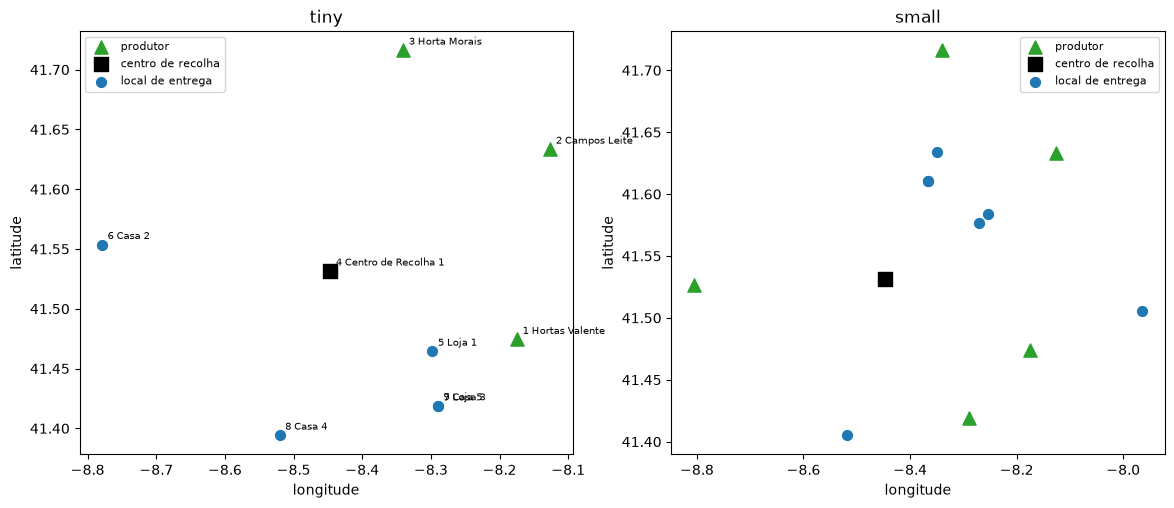

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_locations(tiny, axes[0])
axes[0].set_title("tiny")
plot_locations(small, axes[1], labels=False)
axes[1].set_title("small");

- Os dados estão limpos: a auditoria não encontra erros em nenhum dos datasets.
- As restrições que mais apertam são as temporais. No tiny, três encomendas passam a noite no armazém, com 25 a 29 h entre a recolha e a entrega, por isso o limite de 24 h conta.
- Todos os locais ficam a 19–38 km do centro, por isso o número de viagens domina o custo.
- No small, a procura (580 kg) já passa a capacidade da frota (550 kg).

## 3. Modelação

- O tempo conta-se em minutos desde o início do horizonte.
- Uma **recolha** junta as linhas do mesmo produtor com janelas que se intersetam (no tiny, 40 linhas dão 6 recolhas). Uma **entrega** é uma encomenda.
- Cada veículo faz **viagens** que saem do centro e voltam lá. Uma viagem só tem recolhas ou só entregas e não passa a meia-noite.
- Um veículo pode entregar o que outro recolheu, depois de descarregado no armazém.
- Os veículos saem a tempo de chegar à primeira paragem quando a janela abre.
- Objetivo: minimizar os km. A refrigeração é ignorada, porque os dados não dizem que produtos precisam de frio.

`evaluate(problem, solution)` simula uma solução `{veículo: [viagens]}` e devolve os km e as violações. A pesquisa local usa um custo penalizado: `km + 100·(atraso + excesso de carga + excesso de permanência) + 10 000·(erros estruturais)`.

In [5]:
# os 18 pedidos do tiny depois do agrupamento
rows = [dict(id=request_id, tipo=request.kind, local=request.loc,
             janela=f"{tiny.clock(request.tw[0])} – {tiny.clock(request.tw[1])}",
             kg=request.weight, linhas=len(request.items), depende_de=", ".join(request.deps))
        for request_id, request in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


In [6]:
# uma solução feita à mão e uma variante inválida, com a entrega D3 antes das recolhas
manual = {1: [["P4", "P6", "P2"], ["D3"]],
          2: [["P5", "P1", "P3"], ["D4", "D11", "D10", "D12"], ["D2", "D9", "D8"], ["D1", "D6", "D5", "D7"]]}
broken = {1: [["D3"], ["P4", "P6", "P2"]], 2: manual[2]}
pd.DataFrame({"manual": evaluate(tiny, manual).summary(), "inválida": evaluate(tiny, broken).summary()})

,manual,inválida
km,663.81,397.58
feasible,True,False
trips,6,3
late_min,0.0,0.0
over_kg,0.0,0.0
dwell_excess_min,0.0,0.0
unserved,0,0
deadlock,0,8
overnight,0,0
makespan_min,2243.5,2078.5


`check_solution` volta a verificar cada solução linha a linha contra os CSV originais, sem usar o simulador.

In [7]:
manual_eval = evaluate(tiny, manual)
check = check_solution(tiny, manual_eval)
print("simulador:", round(manual_eval.km, 2), "km, viável =", manual_eval.feasible,
      "| verificador:", check.valid, round(check.km, 2), "km")
print("solução inválida:", check_solution(tiny, evaluate(tiny, broken)).errors[:3])

simulador: 663.81 km, viável = True | verificador: True 663.81 km
solução inválida: ['linha 1: pickup feito 0 vezes (esperado 1)', 'linha 1: unload feito 0 vezes (esperado 1)', 'linha 1: load feito 0 vezes (esperado 1)']


## 4. Pesquisa informada

Um estado é uma solução parcial: posição, hora e viagem em curso de cada veículo, pedidos servidos e chegadas ao armazém. Cada ação faz um veículo visitar um pedido ou voltar ao centro, e o custo são os km. Podamos estados sem saída e estados dominados.

Numa segunda formulação, cada ação é uma viagem completa, tirada de um catálogo de viagens viáveis calculado antes da pesquisa.

Heurísticas, todas admissíveis:

- **h1**: distância ao pedido mais longe, ida e volta.
- **h2**: soma dos arcos mais baratos que cada local ainda precisa.
- **h3**: árvore de cobertura mínima por grupo (dia, tipo).
- **h4**: ótimo exato de um problema relaxado, por grupo.

O Greedy usa f = h e o A\* f = g + h.

In [8]:
# valor de cada heurística no estado inicial
pd.DataFrame({name: {heuristic_name: round(heuristic(problem, State.initial(problem)), 2)
                     for heuristic_name, heuristic in HEURISTICS.items()}
              for name, problem in PROBLEMS.items()})

,tiny,small
h1_max_detour,75.32,104.66
h2_min_arcs,395.95,419.05
h3_mst,441.83,469.13
h4_relaxed,533.09,757.84
h0_zero,0.00,0.00


### 4.1 Greedy no tiny

O Greedy segue sempre o estado que parece mais perto do fim (f = h). É rápido e dá uma primeira solução, mas sem garantia de ótimo.

In [ ]:
greedy_results = {}
for name, heuristic in HEURISTICS.items():
    greedy_results[name] = greedy(tiny, heuristic)
    print(name, greedy_results[name].summary())

### 4.2 A\* nos dois datasets

O A\* junta os km já feitos à estimativa do que falta (f = g + h). Com uma heurística admissível, a primeira solução que encontra é ótima. O A\* ponderado dá mais peso à heurística (f = g + w·h) para expandir menos nós, aceitando soluções até w vezes acima do ótimo.

Demora cerca de 10 minutos.

In [ ]:
def run(name, heuristic_name, result):
    return dict(dataset=name, heuristic_name=heuristic_name, **result.summary())


rows = []
for name, problem in PROBLEMS.items():
    budget = 1_000_000 if name == "tiny" else 30_000
    rows += [run(name, hn, greedy(problem, h, max_expansions=100_000)) for hn, h in HEURISTICS.items()]
    rows += [run(name, hn, astar(problem, h, max_expansions=budget)) for hn, h in HEURISTICS.items()]
    rows += [run(name, hn, astar_trips(problem, HEURISTICS[hn], time_limit=60)) for hn in ("h3_mst", "h4_relaxed")]
informed = pd.DataFrame(rows)
informed[["dataset", "algorithm", "heuristic_name", "cost_km", "expanded", "generated", "pruned", "seconds", "complete"]]

In [ ]:
# A* ponderado no tiny, com h3
for weight in (1.5, 2.0):
    print(weight, weighted_astar(tiny, h_mst, weight).summary())

### 4.3 A\* por viagens

É o mesmo A\*, mas cada ação é uma viagem inteira. Há muito menos caminhos para a mesma solução, por isso a pesquisa fica muito mais pequena.

In [ ]:
optimal = {}
for name, problem in PROBLEMS.items():
    start = time.perf_counter()
    trip_catalog = catalog(problem)
    catalog_seconds = time.perf_counter() - start
    optimal[name] = astar_trips(problem, h_relaxed)
    print(f"{name}: catálogo com {trip_catalog.raw_orders} ordens -> {len(trip_catalog.options)} opções "
          f"({catalog_seconds:.1f} s) | {optimal[name].summary()}")

### 4.4 Rotas ótimas do tiny

In [ ]:
best_tiny = optimal["tiny"].solution
tiny_eval = evaluate(tiny, best_tiny)
print(tiny_eval.summary())
print("verificador:", check_solution(tiny, tiny_eval).valid)
print_routes(best_tiny)
plot_routes(tiny, best_tiny, f"tiny: solução ótima do A*, {tiny_eval.km:.2f} km");

,vehicle,trip,stop,kind,arrival,start,window,weight
0,1,0,W,P,NaN,31 07:06,,NaN
1,1,0,P6,P,31 07:45,31 07:45,31 07:45-31 09:45,32.1
2,1,0,P4,P,31 08:29,31 08:29,31 08:15-31 10:00,29.9
3,1,0,P2,P,31 09:11,31 09:11,31 09:00-31 11:15,41.1
4,1,0,W,P,31 10:01,NaN,,NaN
5,1,1,W(carga),D,NaN,31 10:31,,NaN
6,1,1,D1,D,31 11:03,31 11:03,31 10:30-31 12:45,22.0
7,1,1,D6,D,31 11:13,31 11:13,31 10:45-31 13:15,16.7
8,1,1,D7,D,31 11:23,31 11:23,31 10:45-31 13:30,33.5
9,1,1,D5,D,31 11:42,31 11:42,31 10:30-31 12:30,9.3


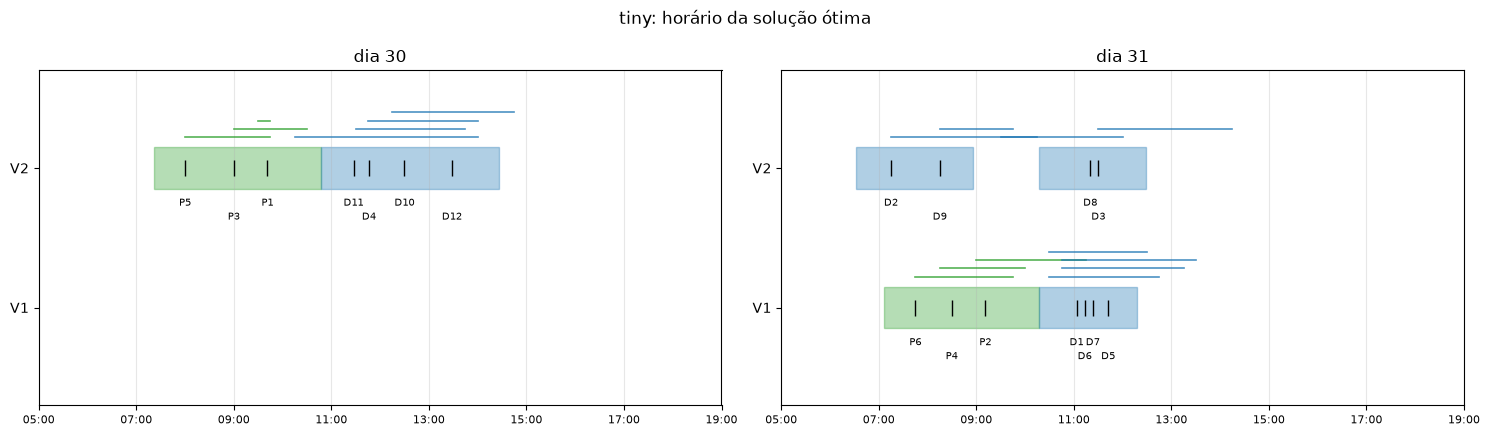

In [14]:
plot_gantt(tiny, tiny_eval, "tiny: horário da solução ótima");
schedule_table(tiny, tiny_eval)

Com h1 e h2, o A\* não encontra solução no tiny em 1 000 000 expansões; com h3 precisa de 709 786, e com h4 de 7 302. Por viagens e com h4, bastam 7 expansões no tiny e 19 no small. Como a h4 vale o custo da solução logo no estado inicial, os ótimos ficam provados: **533,09 km** no tiny e **757,84 km** no small. O Greedy fica 15–17% acima.

## 5. Pesquisa local

Partimos da solução do Greedy (h3). Os movimentos são mudar um pedido de sítio, trocar dois pedidos e inverter um troço de uma viagem.

- **Hill Climbing *steepest***: passa sempre para o melhor vizinho. É simples e rápido, mas para no primeiro ótimo local.
- **Hill Climbing *first improvement***: passa para o primeiro vizinho que melhora, com passos mais baratos.
- **Simulated Annealing**: aceita às vezes pioras (com probabilidade exp(−Δ/T), cada vez menor) para conseguir sair de ótimos locais.

In [15]:
start = greedy_results["h3_mst"].solution
hc_steepest = hill_climbing(tiny, start, "steepest")
hc_first = hill_climbing(tiny, start, "first", seed=0)
annealing = simulated_annealing(tiny, start, t0=30, alpha=0.9998, iters=30_000, seed=0)
pd.DataFrame([hc_steepest.summary(), hc_first.summary(), annealing.summary()])

,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,HC-steepest,625.46,533.09,14.77,True,5,2714,0.130
1,HC-first,625.46,533.09,14.77,True,5,705,0.049
2,SA,625.46,533.09,14.77,True,30000,30000,1.394


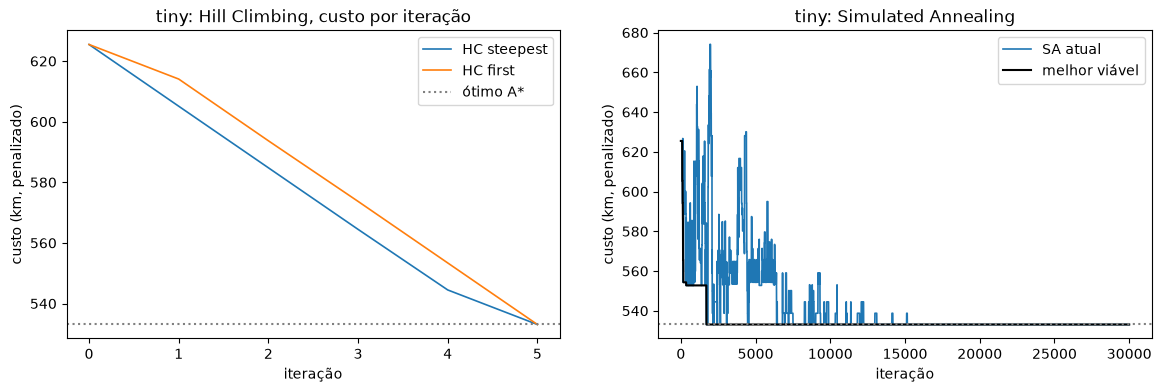

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({"HC steepest": dict(current=hc_steepest.history), "HC first": dict(current=hc_first.history)},
               "tiny: Hill Climbing, custo por iteração", ax=axes[0])
axes[0].axhline(tiny_eval.km, color="grey", ls=":", label="ótimo A*")
axes[0].legend()
plot_histories({"SA atual": dict(current=annealing.history)}, "tiny: Simulated Annealing", ax=axes[1], cap=800)
best_so_far = pd.Series(annealing.best_history).replace(float("inf"), None)
axes[1].plot(best_so_far.index, best_so_far.values, color="black", lw=1.5, label="melhor viável")
axes[1].axhline(tiny_eval.km, color="grey", ls=":")
axes[1].legend();

In [17]:
print("movimentos aceites pelo HC steepest:")
for move in hc_steepest.moves:
    print("  ", move)

movimentos aceites pelo HC steepest:
   ('relocate', 'P6', 1, 0, 0)
   ('relocate', 'P2', 1, 0, 2)
   ('relocate', 'P1', 2, 0, 2)
   ('swap', 'D10', 'D11')
   ('relocate', 'D5', 1, 1, 0)


In [ ]:
runs = {}
for name, problem in PROBLEMS.items():
    initial = greedy(problem, h_mst).solution
    runs[name, "HC-steepest", 0] = hill_climbing(problem, initial, "steepest")
    for seed in range(5):
        runs[name, "HC-first", seed] = hill_climbing(problem, initial, "first", seed=seed)
        runs[name, "SA", seed] = simulated_annealing(problem, initial, t0=30, alpha=0.9998, iters=30_000, seed=seed)
local = pd.DataFrame([dict(dataset=name, seed=seed, **result.summary()) for (name, _, seed), result in runs.items()])
local.groupby(["dataset", "algorithm"]).agg(
    km_min=("final_km", "min"), km_media=("final_km", "mean"), km_max=("final_km", "max"),
    segundos=("seconds", "mean"), avaliacoes=("evaluated", "mean"), corridas=("seed", "count")).round(2)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({f"{algorithm}_{seed}": dict(current=result.history) for (name, algorithm, seed), result in runs.items()
                if name == "small" and algorithm.startswith("HC")}, "small: Hill Climbing", ax=axes[0])
plot_histories({f"SA_{seed}": dict(current=[km if km != float("inf") else None for km in result.best_history])
                for (name, algorithm, seed), result in runs.items() if name == "small" and algorithm == "SA"},
               "small: SA, melhor solução viável até cada iteração", ax=axes[1]);

No tiny, os três chegam ao ótimo. No small, o HC *steepest* fica em 799,35 km (5,5% acima do ótimo) e a melhor corrida do SA em 771,69 km (1,8%), mas em média o SA não é melhor do que o HC.

## 6. CSP

- **Variáveis**: uma por pedido.
- **Domínios**: (veículo, dia, posição da viagem), com um modelo fixo de viagens por dia (`D-P-D-D-P-D-D`). Pedidos com o mesmo valor formam uma viagem.
- **Restrições binárias**: capacidade e janelas compatíveis na mesma viagem, recolha antes da entrega no mesmo veículo, e uma ordem das viagens que respeite as janelas.
- **Restrição global**: existe um horário viável (verificado com o simulador).
- **Restrição suave**: minimizar os km. A ordenação de valores põe primeiro o valor que acrescenta menos km, e o branch & bound continua à procura de soluções mais baratas.

Algoritmos:

- **Backtracking**: atribui um pedido de cada vez e recua quando uma restrição falha.
- **MRV**: escolhe primeiro o pedido com menos opções, onde é mais provável falhar.
- **Ordem *soft***: experimenta primeiro o valor que acrescenta menos km, para a primeira solução já ser barata.
- **Forward checking**: depois de cada atribuição, tira aos outros pedidos os valores que deixaram de ser possíveis, para detetar becos sem saída mais cedo.
- **MAC (AC-3)**: propaga essas remoções em cadeia, à custa de mais trabalho por nó. O FC global faz o mesmo contra o horário completo.
- **Branch & bound**: depois da primeira solução, continua a procurar só soluções mais baratas.

In [20]:
tiny_csp = RoutingCSP(tiny)
print("variáveis:", len(tiny_csp.vars), "| valores iniciais:", sum(map(len, tiny_csp.domains.values())),
      "| pares com restrição binária:", sum(map(len, tiny_csp.neigh.values())) // 2)
print("domínio de D2:", tiny_csp.domains["D2"])

variáveis: 18 | valores iniciais: 144 | pares com restrição binária: 149
domínio de D2: [(1, 1, 0), (1, 1, 2), (1, 1, 3), (1, 1, 5), (1, 1, 6), (2, 1, 0), (2, 1, 2), (2, 1, 3), (2, 1, 5), (2, 1, 6)]


In [21]:
rows = []
for inference in ("none", "fc", "mac"):
    for global_fc in (False, True):
        rows.append(solve(tiny, inference=inference, global_fc=global_fc).summary())
pd.DataFrame(rows)

,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds
0,none,mrv,soft,False,False,viável,659.27,25,7,26,0,1,0.014
1,none,mrv,soft,True,False,viável,621.57,18,0,1258,60,1,0.055
2,fc,mrv,soft,False,False,viável,659.27,21,3,22,37,1,0.005
3,fc,mrv,soft,True,False,viável,621.57,18,0,1206,60,1,0.056
4,mac,mrv,soft,False,False,viável,659.27,21,3,22,37,1,0.015
5,mac,mrv,soft,True,False,viável,621.57,18,0,1201,60,1,0.063


In [ ]:
# backtracks de cada configuração (orçamento de 20 000 atribuições por corrida)
rows = []
for name, problem in PROBLEMS.items():
    for inference in ("none", "fc", "mac"):
        for var_order in ("static", "mrv"):
            for value_order in ("static", "soft"):
                for global_fc in (False, True):
                    result = solve(problem, inference=inference, var_order=var_order, value_order=value_order,
                                   global_fc=global_fc, max_assignments=20_000, time_limit=90)
                    rows.append(dict(dataset=name, **result.summary()))
    result = solve(problem, global_fc=True, optimize=True, max_assignments=20_000, time_limit=600)
    rows.append(dict(dataset=name, **result.summary()))
csp_results = pd.DataFrame(rows)
first_solutions = csp_results[~csp_results.optimize]
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="backtracks", aggfunc="first")

In [23]:
# km da primeira solução de cada configuração
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="cost_km", aggfunc="first")

dataset                           small            tiny        
global_fc                         False   True    False   True 
inference var_order value_order                                
fc        mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
mac       mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
none      mrv       soft         895.42  841.05  659.27  621.57
                    static       819.13  865.24  659.27  659.27
          static    soft            NaN  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27

In [24]:
csp_results[csp_results.optimize]

,dataset,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds,feasible,item_check,km_check
24,tiny,mac,mrv,soft,True,True,melhor encontrada (limite),621.57,20000,19985,435282,4365,1,30.171,True,True,621.57
49,small,mac,mrv,soft,True,True,melhor encontrada (limite),792.71,20000,19976,412028,8627,4,45.076,True,True,792.71


No small, sem inferência e com ordem estática, o backtracking não encontra solução em 20 000 atribuições; com forward checking ou MAC e MRV bastam 0–1 backtracks. O branch & bound chega a 792,71 km no small (4,6% acima do ótimo), sem provar que é ótimo.

## 7. Análise de resultados

In [ ]:
rows = []
for dataset in ("tiny", "small"):
    for algorithm in ("Greedy", "A*", "A*-viagens"):
        for heuristic in ("h1_max_detour", "h2_min_arcs", "h3_mst", "h4_relaxed"):
            match = informed[(informed.dataset == dataset) & (informed.algorithm == algorithm)
                             & (informed.heuristic_name == heuristic)]
            if len(match):
                run = match.iloc[0]
                rows.append(dict(dataset=dataset, metodo=f"{algorithm} {heuristic.split('_')[0]}", km=run.cost_km,
                                 segundos=run.seconds, esforco=f"{int(run.expanded)} expansões",
                                 completo=run.complete))
    for algorithm in ("HC-steepest", "HC-first", "SA"):
        runs = local[(local.dataset == dataset) & (local.algorithm == algorithm)]
        rows.append(dict(dataset=dataset, metodo=f"{algorithm} (melhor de {len(runs)})", km=runs.final_km.min(),
                         segundos=runs.seconds.mean(), esforco=f"{int(runs.evaluated.mean())} avaliações",
                         completo=None))
    mrv_soft = (csp_results.var_order == "mrv") & (csp_results.value_order == "soft") & ~csp_results.optimize
    csp_configs = [
        ("CSP FC+MRV+soft", mrv_soft & (csp_results.inference == "fc") & ~csp_results.global_fc),
        ("CSP MAC+MRV+soft", mrv_soft & (csp_results.inference == "mac") & ~csp_results.global_fc),
        ("CSP MAC+MRV+soft+FC global", mrv_soft & (csp_results.inference == "mac") & csp_results.global_fc),
        ("CSP branch & bound", csp_results.optimize),
    ]
    for label, mask in csp_configs:
        run = csp_results[(csp_results.dataset == dataset) & mask].iloc[0]
        rows.append(dict(dataset=dataset, metodo=label, km=run.cost_km, segundos=run.seconds,
                         esforco=f"{int(run.backtracks)} backtracks", completo=None))
comparison = pd.DataFrame(rows)
comparison.round(2)

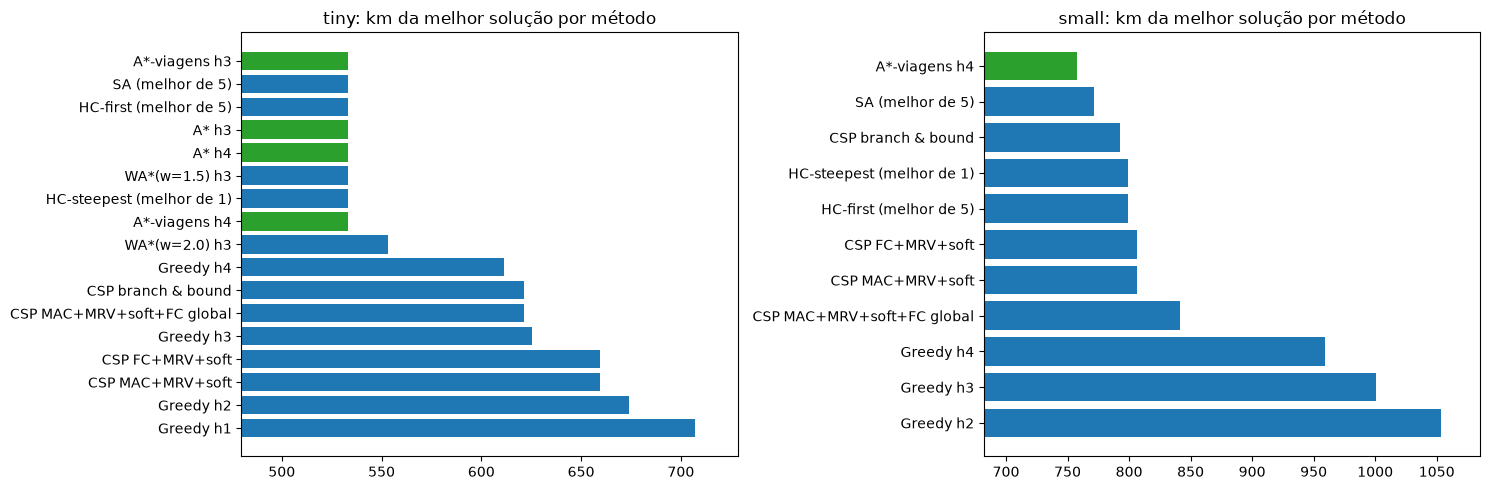

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, dataset in zip(axes, ("tiny", "small")):
    methods = comparison[(comparison.dataset == dataset) & comparison.km.notna()].sort_values("km")
    ax.barh(methods.metodo, methods.km,
            color=["tab:green" if method.startswith("A*") else "tab:blue" for method in methods.metodo])
    ax.set_xlim(methods.km.min() * 0.9, methods.km.max() * 1.03)
    ax.set_title(f"{dataset}: km da melhor solução por método")
    ax.invert_yaxis()
fig.tight_layout()

### 7.1 Melhor solução do small

In [ ]:
best_small = optimal["small"].solution
small_eval = evaluate(small, best_small)
print(small_eval.summary())
print("verificador:", check_solution(small, small_eval).valid)
print_routes(best_small)
plot_routes(small, best_small, f"small: solução ótima do A* por viagens, {small_eval.km:.2f} km");

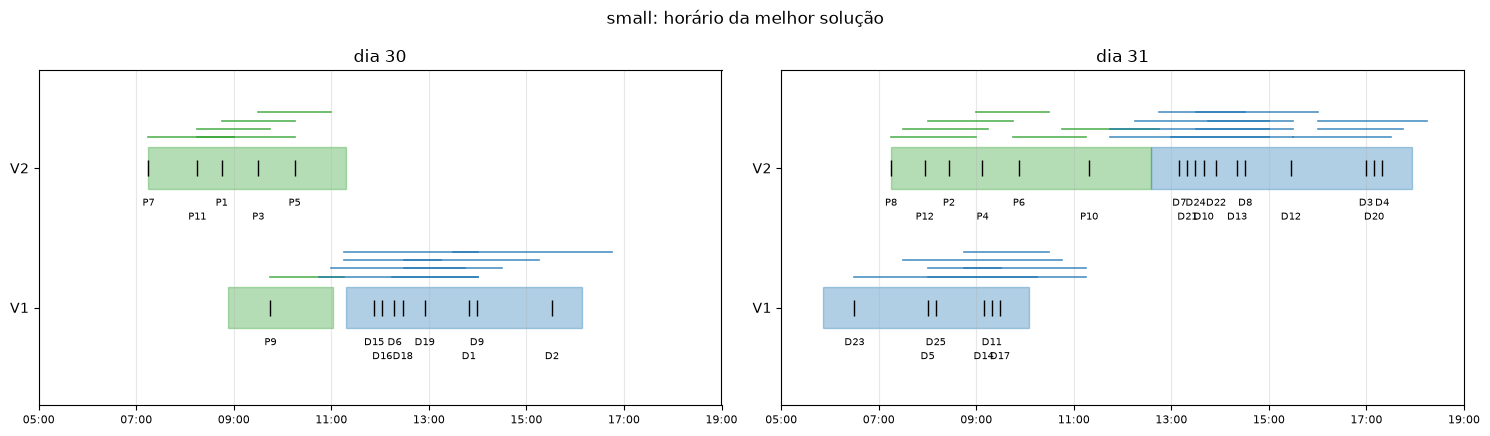

In [28]:
plot_gantt(small, small_eval, "small: horário da melhor solução");

### 7.2 Análise crítica

- **Qualidade**: o A\* por viagens com h4 prova o ótimo nos dois datasets. A pesquisa local fica a 0–10% do ótimo e o CSP a 5–24%.
- **Comparação**: o A\* exato só escala com uma boa heurística e ações ao nível da viagem. A pesquisa local é rápida e escalaria melhor, mas sem garantias. O CSP dá depressa uma solução viável.
- **Melhorias**: viagens mistas (recolhas e entregas na mesma volta), recolhas parciais, uma vizinhança maior na pesquisa local e CP-SAT para instâncias maiores.

Tempos de execução (uma execução num portátil):

| Método | tiny | small |
|---|---|---|
| Greedy | milissegundos | até 0,95 s (h4) |
| A\* paragem a paragem | minutos (h3) | não termina |
| A\* por viagens (h4) | centésimas de segundo | cerca de 3 s, mais 18–36 s para o catálogo (feito uma vez) |
| Hill Climbing | centésimas a décimas de segundo | 0,4–1,0 s |
| SA (30 000 iterações) | 1,2–1,4 s | 2,0–2,5 s |
| CSP com FC ou MAC | centésimas de segundo | centésimas de segundo, 0,2–0,3 s com FC global |
| CSP com branch & bound | esgota o orçamento | esgota o orçamento |

## 8. Conclusão

Provámos o ótimo dos dois datasets (533,09 e 757,84 km), com todas as soluções confirmadas pelo verificador. O que mais pesou foi a formulação: com ações ao nível da viagem e uma heurística forte, o A\* passa de não terminar a resolver o small em segundos. A maior dificuldade foi a dependência entre veículos através do armazém.